# Стратифицированная оценка эффекта

Сравнение naive- и stratified-оценки эффекта на трёх сегментах пользователей: new, regular, vip. Данные синтетические, истинный эффект 0.8.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'axes.axisbelow': True})

In [2]:
def generate_experiment(seed=123):
    rng = np.random.default_rng(seed)
    n = 18_000

    segment = rng.choice(
        ['new', 'regular', 'vip'],
        size=n,
        p=[0.55, 0.30, 0.15]
    )

    variant = rng.integers(0, 2, size=n)

    baseline = np.select(
        [segment == 'new', segment == 'regular', segment == 'vip'],
        [3.5, 7.5, 16.0]
    )

    true_effect = 0.8
    noise = rng.normal(0.0, 5.5, n)
    y = baseline + true_effect * variant + noise

    return pd.DataFrame({
        'segment': segment,
        'variant': variant,
        'y': y,
    })


exp = generate_experiment(seed=123)
exp.head()

,segment,variant,y
0,regular,0,0.5616
1,new,0,2.3353
2,new,0,6.4584
3,new,1,5.8533
4,new,1,4.0095


## 1. Naive estimator

$$\hat\tau_{\mathrm{naive}} = \bar{Y}_T - \bar{Y}_C, \qquad
\operatorname{SE} = \sqrt{\frac{s_T^2}{n_T} + \frac{s_C^2}{n_C}}$$

`effect_naive` и `se_naive` — разность средних по всей выборке и её стандартная ошибка.

In [3]:
treatment = exp.loc[exp['variant'] == 1, 'y']
control = exp.loc[exp['variant'] == 0, 'y']
effect_naive = treatment.mean() - control.mean()
se_naive = np.sqrt(treatment.var(ddof=1) / len(treatment) + control.var(ddof=1) / len(control))

print(f'effect_naive = {effect_naive:.4f}, se_naive = {se_naive:.4f}')

effect_naive = 0.7055, se_naive = 0.1039


## 2. Таблица по стратам

$$\hat\tau_h = \bar{Y}_{T,h} - \bar{Y}_{C,h}, \qquad w_h = \frac{N_h}{N}, \qquad
\widehat{\operatorname{Var}}(\hat\tau_h) = \frac{s_{T,h}^2}{n_{T,h}} + \frac{s_{C,h}^2}{n_{C,h}}$$

`strata_table` — по строке на сегмент: вес `weight`, эффект `tau_h` и дисперсия `var_h`.

In [4]:
rows = []
for h, part in exp.groupby('segment'):
    treatment = part.loc[part['variant'] == 1, 'y']
    control = part.loc[part['variant'] == 0, 'y']
    t_h = treatment.mean() - control.mean()
    w_h = len(part) / len(exp)
    var_h = treatment.var(ddof=1) / len(treatment) + control.var(ddof=1) / len(control)

    rows.append({
        'segment': h,
        'weight': w_h,
        'tau_h': t_h,
        'var_h': var_h,
    })
strata_table = pd.DataFrame(rows)
strata_table

,segment,weight,tau_h,var_h
0,new,0.5538,0.8506,0.0123
1,regular,0.3002,0.6729,0.0219
2,vip,0.1460,0.3023,0.0461


## 3. Stratified estimator

$$\hat\tau_{\mathrm{strat}} = \sum_{h} w_h \hat\tau_h, \qquad
\operatorname{SE} = \sqrt{\sum_{h} w_h^2\,\widehat{\operatorname{Var}}(\hat\tau_h)}$$

`effect_strat` — взвешенная сумма `tau_h`, `se_strat` — корень из взвешенной суммы `var_h`.

In [5]:
effect_strat = np.sum(strata_table['weight'] * strata_table['tau_h'])
se_strat = np.sqrt(np.sum((strata_table['weight'] ** 2) * strata_table['var_h']))

print(f'effect_strat = {effect_strat:.4f}, se_strat = {se_strat:.4f}')

effect_strat = 0.7172, se_strat = 0.0820


## 4. Сравнение naive и stratified

`comparison` — эффект, SE и 95% ДИ (`effect ± 1.96 · se`) двух методов. `sample_size_ratio` показывает, во сколько раз меньше пользователей нужно stratified-оценке для той же SE.

In [6]:
naive_effect = {
    'effect': effect_naive,
    'se': se_naive,
    'ci_left': effect_naive - 1.96 * se_naive,
    'ci_right': effect_naive + 1.96 * se_naive,
}
strat_eff = {
    'effect': effect_strat,
    'se': se_strat,
    'ci_left': effect_strat - 1.96 * se_strat,
    'ci_right': effect_strat + 1.96 * se_strat,
}
comparison = pd.DataFrame([
    {'method': 'naive', **naive_effect},
    {'method': 'stratified', **strat_eff}
])
comparison['ci_width'] = comparison['ci_right'] - comparison['ci_left']

ci_reduction = 1 - comparison.loc[1, 'ci_width'] / comparison.loc[0, 'ci_width']
sample_size_ratio = (se_naive / se_strat) ** 2
print(f'ДИ уже на {ci_reduction:.1%}, sample_size_ratio = {sample_size_ratio:.2f}')
comparison

ДИ уже на 21.1%, sample_size_ratio = 1.61


,method,effect,se,ci_left,ci_right,ci_width
0,naive,0.7055,0.1039,0.5018,0.9092,0.4075
1,stratified,0.7172,0.0820,0.5564,0.8781,0.3216


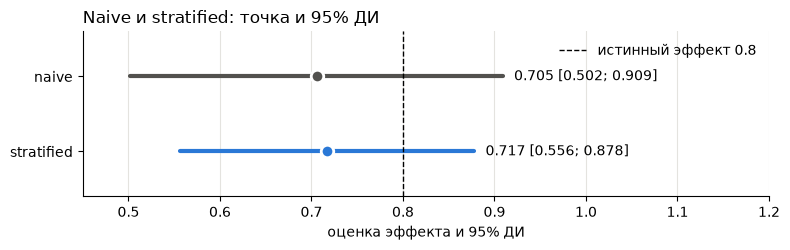

In [7]:
fig, ax = plt.subplots(figsize=(8, 2.6))
for i, (row, color) in enumerate(zip(comparison.itertuples(), ['#52514e', '#2a78d6'])):
    ax.plot([row.ci_left, row.ci_right], [i, i], color=color, lw=3, solid_capstyle='round')
    ax.plot(row.effect, i, 'o', color=color, ms=9, mec='white', mew=2)
    ax.annotate(f'{row.effect:.3f} [{row.ci_left:.3f}; {row.ci_right:.3f}]', (row.ci_right, i),
                xytext=(8, 0), textcoords='offset points', va='center', fontsize=10)
ax.axvline(0.8, color='black', ls='--', lw=1, label='истинный эффект 0.8')
ax.set_yticks([0, 1], comparison['method'])
ax.set_ylim(1.6, -0.6)
ax.set_xlim(0.45, 1.2)
ax.grid(axis='y', visible=False)
ax.set_xlabel('оценка эффекта и 95% ДИ')
ax.set_title('Naive и stratified: точка и 95% ДИ', loc='left')
ax.legend(frameon=False, loc='upper right')
fig.tight_layout()
fig.savefig('../images/stratification_ci.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Проверка симуляцией

500 повторов эксперимента с разными сидами. Сравниваются дисперсия оценок двух методов и покрытие 95% ДИ, то есть доля интервалов, которые содержат 0.8.

In [8]:
def naive_and_strat(df):
    t = df.loc[df['variant'] == 1, 'y']
    c = df.loc[df['variant'] == 0, 'y']
    naive = (t.mean() - c.mean(), np.sqrt(t.var(ddof=1) / len(t) + c.var(ddof=1) / len(c)))

    effect, var = 0.0, 0.0
    for _, part in df.groupby('segment'):
        t_h = part.loc[part['variant'] == 1, 'y']
        c_h = part.loc[part['variant'] == 0, 'y']
        w_h = len(part) / len(df)
        effect += w_h * (t_h.mean() - c_h.mean())
        var += w_h ** 2 * (t_h.var(ddof=1) / len(t_h) + c_h.var(ddof=1) / len(c_h))
    return {'naive': naive, 'stratified': (effect, np.sqrt(var))}


rows = []
for seed in range(500):
    for method, (effect, se) in naive_and_strat(generate_experiment(seed)).items():
        rows.append({'method': method, 'effect': effect, 'se': se})

sim = pd.DataFrame(rows)
sim['covers'] = (sim['effect'] - 1.96 * sim['se'] <= 0.8) & (0.8 <= sim['effect'] + 1.96 * sim['se'])

sim_summary = sim.groupby('method').agg(
    mean_effect=('effect', 'mean'),
    var_effect=('effect', 'var'),
    mean_se=('se', 'mean'),
    coverage=('covers', 'mean'),
)
var_reduction = 1 - sim_summary.loc['stratified', 'var_effect'] / sim_summary.loc['naive', 'var_effect']
se_var_reduction = 1 - (sim_summary.loc['stratified', 'mean_se'] / sim_summary.loc['naive', 'mean_se']) ** 2
print(f'Снижение дисперсии оценки: {var_reduction:.1%} по разбросу оценок, {se_var_reduction:.1%} по средним SE')
sim_summary

Снижение дисперсии оценки: 42.0% по разбросу оценок, 38.3% по средним SE


,mean_effect,var_effect,mean_se,coverage
method,,,,
naive,0.7973,0.0117,0.1044,0.9500
stratified,0.8011,0.0068,0.0820,0.9540


## Что сделано

- Вручную посчитаны naive-оценка и stratified-оценка, собрана таблица по сегментам `strata_table`.
- Stratified-оценка: 0.717 (SE 0.082), naive: 0.706 (SE 0.104). 95% ДИ уже на 21%, для той же точности нужно в 1.6 раза меньше пользователей.
- В 500 симуляциях обе оценки несмещённые, покрытие 95% ДИ 95%. Дисперсия stratified-оценки ниже на 38–42%.